# Exploração da tabela de consumo

Esta análise valida a tabela antes do baseline: distribuição dos alvos, concentração por canal e corte temporal de avaliação.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "scripts").is_dir() and (p / "src").is_dir())
TABLE_PATH = ROOT / 'data' / 'gold' / 'pilot_consumption_table.csv'

data = pd.read_csv(TABLE_PATH, parse_dates=['published_at'])
data.shape, data['channel_id'].nunique()

((1842, 47), 12)

In [2]:
required_columns = {
    'video_id', 'channel_id', 'published_at', 'baseline_log_likes',
    'target_log_likes', 'target_relative_to_prior_median', 'split'
}
assert required_columns.issubset(data.columns)
assert data['video_id'].is_unique
assert data['split'].isin(['train', 'test']).all()

feature_columns = [
    'duration_seconds', 'channel_prior_posts', 'channel_prior_median_likes',
    'days_since_previous_post', 'publish_hour_utc', 'publish_weekday',
    'title_length', 'description_length', 'tag_count', 'baseline_log_likes',
]
data[feature_columns + ['target_log_likes', 'target_relative_to_prior_median']].isna().sum()

duration_seconds                   0
channel_prior_posts                0
channel_prior_median_likes         0
days_since_previous_post           0
publish_hour_utc                   0
publish_weekday                    0
title_length                       0
description_length                 0
tag_count                          0
baseline_log_likes                 0
target_log_likes                   0
target_relative_to_prior_median    0
dtype: int64

## Distribuição dos alvos

O primeiro modelo usará `target_log_likes`, porque a escala de curtidas é muito assimétrica. O alvo relativo continua disponível para experimento posterior.

,target_log_likes,target_relative_to_prior_median
0.00,0.000,0.025
0.25,2.708,0.600
0.50,3.638,0.976
0.75,5.740,1.733
0.90,7.504,3.628
0.95,8.162,7.462
1.00,10.285,1246.375


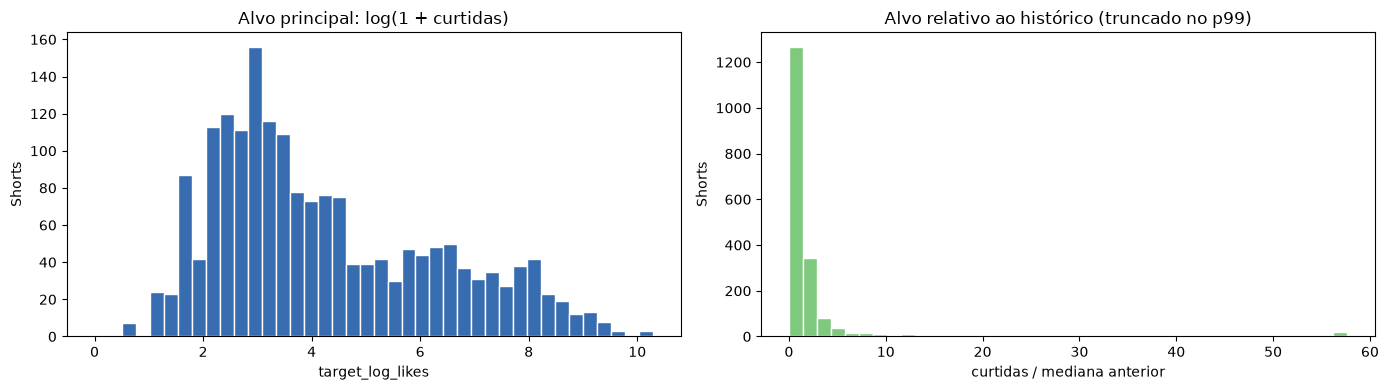

In [3]:
quantiles = data[['target_log_likes', 'target_relative_to_prior_median']].quantile(
    [0, .25, .5, .75, .9, .95, 1]
).round(3)
display(quantiles)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(data['target_log_likes'], bins=40, color='#386cb0', edgecolor='white')
axes[0].set(title='Alvo principal: log(1 + curtidas)', xlabel='target_log_likes', ylabel='Shorts')

relative_cap = data['target_relative_to_prior_median'].quantile(.99)
axes[1].hist(
    data['target_relative_to_prior_median'].clip(upper=relative_cap),
    bins=40, color='#7fc97f', edgecolor='white'
)
axes[1].set(
    title='Alvo relativo ao histórico (truncado no p99)',
    xlabel='curtidas / mediana anterior', ylabel='Shorts'
)
plt.tight_layout()

## Desbalanceamento por canal

A análise é feita por canal, pois vídeos do mesmo canal compartilham audiência e frequência de publicação.

,channel_name,sector,channel_type,shorts,share,median_likes,train,test
1,C&A Brasil,moda,brand,273,14.8%,7,218,55
4,EstiloRenner,moda,brand,257,14.0%,14,205,52
7,Hyundai Motor Brasil,automotivo,brand,223,12.1%,18,178,45
10,Steal The Look,moda,creator,191,10.4%,39,152,39
6,Honda Automoveis,automotivo,brand,181,9.8%,34,144,37
11,Volkswagen do Brasil,automotivo,brand,156,8.5%,74,124,32
0,Acelerados,automotivo,creator,143,7.8%,265,114,29
2,Carros com Camanzi,automotivo,creator,131,7.1%,826,104,27
8,Mandy Candy,moda,creator,126,6.8%,"3,269",100,26
3,De Carona com Leandro,automotivo,creator,80,4.3%,504,64,16


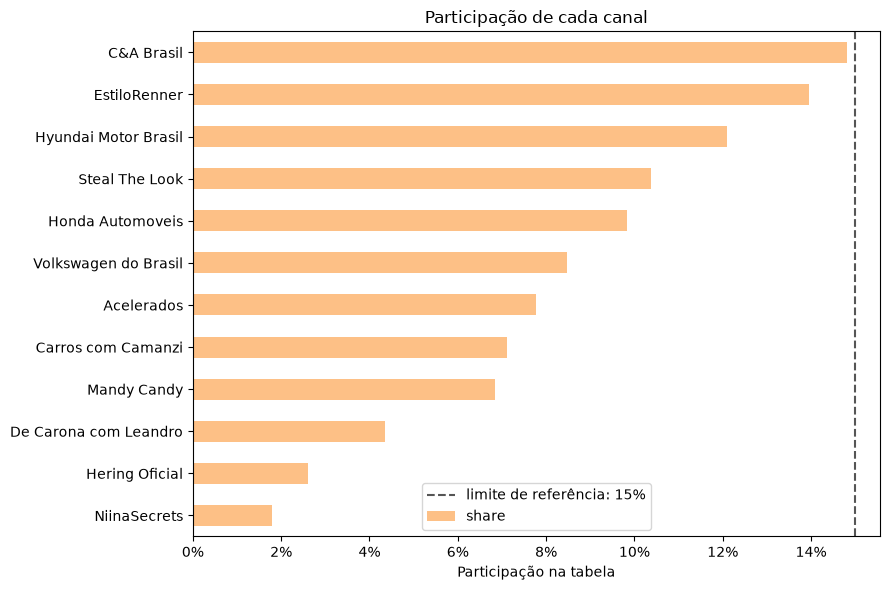

In [4]:
channel_summary = (
    data.groupby(['channel_name', 'sector', 'channel_type'], as_index=False)
    .agg(
        shorts=('video_id', 'size'),
        share=('video_id', lambda values: len(values) / len(data)),
        median_likes=('target_log_likes', lambda values: np.expm1(values).median()),
        train=('split', lambda values: (values == 'train').sum()),
        test=('split', lambda values: (values == 'test').sum()),
    )
    .sort_values('shorts', ascending=False)
)
channel_summary_display = channel_summary.copy()
channel_summary_display['share'] = channel_summary_display['share'].map(lambda value: f'{value:.1%}')
channel_summary_display['median_likes'] = channel_summary_display['median_likes'].map(lambda value: f'{value:,.0f}')
display(channel_summary_display)

plot_data = channel_summary.sort_values('share')
ax = plot_data.plot.barh(x='channel_name', y='share', legend=False, figsize=(9, 6), color='#fdc086')
ax.axvline(.15, linestyle='--', color='#555555', label='limite de referência: 15%')
ax.set(xlabel='Participação na tabela', ylabel='', title='Participação de cada canal')
ax.xaxis.set_major_formatter(lambda value, _: f'{value:.0%}')
ax.legend()
plt.tight_layout()

## Corte temporal formal

O teste contém os 20% mais recentes de **cada** canal. Isso mantém todos os canais no treino e no teste, evita avaliar o futuro com informação futura e produz uma comparação justa com o baseline de mediana histórica.

In [5]:
temporal_audit = (
    data.groupby('channel_name')
    .apply(lambda channel: pd.Series({
        'train_rows': channel['split'].eq('train').sum(),
        'test_rows': channel['split'].eq('test').sum(),
        'last_train': channel.loc[channel['split'].eq('train'), 'published_at'].max(),
        'first_test': channel.loc[channel['split'].eq('test'), 'published_at'].min(),
    }), include_groups=False)
    .sort_values('test_rows', ascending=False)
)
temporal_audit['ordered'] = temporal_audit['last_train'] < temporal_audit['first_test']
assert temporal_audit['ordered'].all()
display(temporal_audit)
print(data['split'].value_counts().rename('rows'))
print(f"Teste: {data['split'].eq('test').mean():.1%} da tabela")

,train_rows,test_rows,last_train,first_test,ordered
channel_name,,,,,
C&A Brasil,218,55,2026-06-22 13:29:20+00:00,2026-06-23 19:52:38+00:00,True
EstiloRenner,205,52,2026-07-08 21:30:37+00:00,2026-07-09 15:00:31+00:00,True
Hyundai Motor Brasil,178,45,2026-06-16 20:28:23+00:00,2026-06-19 12:00:34+00:00,True
Steal The Look,152,39,2026-07-13 20:02:08+00:00,2026-07-13 21:15:22+00:00,True
Honda Automoveis,144,37,2026-05-10 14:21:02+00:00,2026-05-10 19:12:23+00:00,True
Volkswagen do Brasil,124,32,2026-06-11 14:00:21+00:00,2026-06-15 21:00:40+00:00,True
Acelerados,114,29,2026-07-31 15:00:09+00:00,2026-08-01 15:00:05+00:00,True
Carros com Camanzi,104,27,2026-07-14 22:30:05+00:00,2026-07-16 00:05:44+00:00,True
Mandy Candy,100,26,2025-11-04 15:00:07+00:00,2025-11-11 20:45:05+00:00,True


split
train    1467
test      375
Name: rows, dtype: int64
Teste: 20.4% da tabela


## Decisões para o baseline

- Treinar apenas com linhas `split == 'train'` (1.467 linhas).
- Avaliar uma única vez nas 375 linhas de `split == 'test'`.
- Comparar o modelo global multicanal com `baseline_log_likes`, a mediana de curtidas dos posts anteriores de cada canal.
- Usar `target_log_likes` como alvo inicial; o alvo relativo fica reservado para comparação posterior.